### Building Chatbot With Multiple Tools Using Langgraph

#### Aim
Create a chatbot with tool capabilities from arxiv, wikipedia search and some functions

In [1]:

from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper,ArxivAPIWrapper

C:\Users\15715\AppData\Local\Temp\ipykernel_27584\3611065714.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun


In [2]:
api_wrapper_arxiv=ArxivAPIWrapper(top_k_results=2,doc_content_chars_max=500)
arxiv=ArxivQueryRun(api_wrapper=api_wrapper_arxiv)
print(arxiv.name)

arxiv


In [3]:
#arxiv.invoke("Attention is all you need")

In [4]:
import wikipedia
# 1. Set a custom user agent (Wikimedia requires this):
wikipedia.set_user_agent("MyResearchApp/1.0 (contact@example.com)")
api_wrapper_wiki=WikipediaAPIWrapper(top_k_results=1,doc_content_chars_max=500)
wiki=WikipediaQueryRun(api_wrapper=api_wrapper_wiki)
wiki.name

'wikipedia'

In [6]:
wiki.invoke("What is machine learning")

'Page: Machine learning\nSummary: Machine learning (ML) is a field of study in artificial intelligence concerned with the development and study of statistical algorithms that can learn from  data and generalize to unseen data, and thus perform tasks without being explicitly programmed.\nStatistics and mathematical optimisation methods compose the foundations of machine learning. Data mining is a related field of study, focusing on exploratory data analysis (EDA) through unsupervised learning.\nFrom '

In [7]:
from dotenv import load_dotenv
load_dotenv()

import os

os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")


In [19]:
from dotenv import load_dotenv
load_dotenv()
from langchain_community.tools.tavily_search import TavilySearchResults

search_tool = TavilySearchResults(max_results=3)
#tavily = search_tool.invoke("Provide me the recent AI news for march 3rd 202")
#search_tool

In [23]:
### Combine all the tools in the list

tools=[arxiv,wiki,search_tool]

In [24]:
## Initialize my LLM model
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_groq import ChatGroq
llm = ChatGroq(model="Qwen/Qwen3.8-27B")
llm_with_tools=llm.bind_tools(tools)


In [25]:
from pprint import pprint
from langchain_core.messages import AIMessage, HumanMessage
llm_with_tools.invoke([HumanMessage(content=f"What is the recent AI News")])

AIMessage(content='Here is a summary of the most recent and significant AI news, based on current developments up to **May 2024**:\n\n### 1. **Major Model Releases & Updates**\n*   **OpenAI’s GPT-4 Turbo & o1 Preview:** OpenAI has been rolling out updates to GPT-4 Turbo with improved reasoning and longer context windows. More notably, they previewed **o1**, a new model family focused on advanced reasoning, which uses chain-of-thought processes to solve complex problems in math, coding, and science more reliably.\n*   **Anthropic’s Claude 3.5 Sonnet:** Anthropic released Claude 3.5 Sonnet, which is highly competitive with GPT-4 Turbo in coding and reasoning tasks. It has become a favorite among developers for its strong performance in agentic workflows and code generation.\n*   **Google’s Gemini 1.5 Pro:** Google released Gemini 1.5 Pro, featuring a **1 million token context window** (expandable to 2 million in preview), allowing it to process hours of video or thousands of pages of tex

In [26]:
llm_with_tools.invoke([HumanMessage(content=f"What is the recent AI News")]).tool_calls

[{'name': 'tavily_search_results_json',
  'args': {'query': 'latest AI news this week'},
  'id': '4twpzbkn7',
  'type': 'tool_call'}]

In [27]:
## State Schema
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage
from typing import Annotated
from langgraph.graph.message import add_messages
class State(TypedDict):
    messages:Annotated[list[AnyMessage],add_messages]

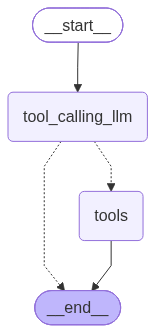

In [30]:
### Entire Chatbot With LangGraph
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

### Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

# Build graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,
)
builder.add_edge("tools", END)


graph = builder.compile()
graph


In [32]:
messages=graph.invoke({"messages":HumanMessage(content="Provide me the top 10 recent AI news for MArch 3rd 2025")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Provide me the top 10 recent AI news for MArch 3rd 2025
================================== Ai Message ==================================
Tool Calls:
  tavily_search_results_json (0myx6nng6)
 Call ID: 0myx6nng6
  Args:
    query: top AI news March 3 2025
  tavily_search_results_json (0j52p3pq5)
 Call ID: 0j52p3pq5
  Args:
    query: artificial intelligence news March 3 2025
================================= Tool Message =================================
Name: tavily_search_results_json

[{"title": "https://aifamelee.io/ai-news-march-3-2025/", "url": "https://aifamelee.io/ai-news-march-3-2025", "content": "### 3. Google Gemini AI Expands Its Capabilities\n\nGoogle has announced exciting updates to its Gemini AI platform, unveiling new models designed for “Flash Thinking Experimental” and “Pro Deep Research.” These enhancements aim to push the boundaries of AI research and practical applications, solidifying

In [33]:
messages=graph.invoke({"messages":HumanMessage(content="What is machine learning")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

What is machine learning
================================== Ai Message ==================================

**Machine learning (ML)** is a field of study in artificial intelligence concerned with the development and study of statistical algorithms that can learn from data and generalize to unseen data, and thus perform tasks without explicit instructions.

In simpler terms, instead of being explicitly programmed with rules (e.g., "if X happens, do Y"), a machine learning system is given a large amount of data and allowed to find patterns and make predictions or decisions on its own.

### Key Concepts:
1. **Learning**: The algorithm improves its performance on a specific task as it is exposed to more data.
2. **Generalization**: The ability of the model to perform well on new, unseen data, not just the data it was trained on.
3. **Data-Driven**: The quality of the model is heavily dependent on the quality a